# Chapter 3: Dimensionality Reduction Techniques

*Summary notebook for **scikit-learn Cookbook, Third Edition** — Chapter 3.*

The chapter's analogy: a recipe is ruined by the wrong *ingredients*. In ML the ingredients are features, and **dimensionality reduction** is how we pick or distil them.

**Recipes covered**
1. Introduction & why it matters
2. PCA (unsupervised, variance-maximising)
3. LDA (supervised, class-separating)
4. t-SNE (non-linear, for visualisation)
5. Choosing a technique & trade-offs
6. Practical exercises (PCA + logistic regression; t-SNE + K-Means)

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
np.random.seed(2024)

## 1. Introduction to Dimensionality Reduction

### Summary
Reducing the number of features while keeping as much useful information as possible. Reasons:

- **Simplify** data (easier to interpret).
- **Cut computational cost**.
- **Improve generalisation** by dropping noisy/redundant features (less overfitting).
- **Enable visualisation** (we can only plot 2–3 dimensions).

### Two families
| Family | Idea | Examples |
|:--|:--|:--|
| **Feature selection** | Keep a *subset* of the original features | Filter (statistics), Wrapper (`RFE`), Embedded (Lasso) |
| **Feature extraction** | Build *new* features as combinations of old ones | PCA, LDA, t-SNE |

### Theory explained — the curse of dimensionality
As the number of dimensions $p$ grows, data becomes sparse: the volume of space grows exponentially, so with a fixed number of samples, points are far apart and *distances become nearly identical*. Distance-based and density-based models degrade and overfit easily. Reducing $p$ fights this.

## 2. PCA — Principal Component Analysis

### Summary
PCA projects data onto new orthogonal axes (**principal components**, PCs) ordered by how much **variance** they capture. It is **unsupervised** (ignores labels). **Always standardize first** — otherwise features with large units dominate the variance.

### Theory explained — how PCA works
1. **Standardize** features (mean 0, variance 1).
2. **Covariance matrix** $\Sigma=\frac1{n-1}\mathbf X^T\mathbf X$ — how features vary together.
3. **Eigen-decomposition** $\Sigma\mathbf v_k=\lambda_k\mathbf v_k$: eigenvectors $\mathbf v_k$ = directions (the PCs); eigenvalues $\lambda_k$ = variance along them.
4. **Select** the top $m$ eigenvectors (largest $\lambda$).
5. **Project:** $\mathbf Z=\mathbf X\mathbf V_m$.

**Explained variance ratio** of PC $k$: $\;\lambda_k/\sum_j\lambda_j$. Components are mutually orthogonal (uncorrelated). (scikit-learn actually uses SVD, which is numerically equivalent and more stable.)

### Setup — the Wine dataset (178 samples, 13 features, 3 classes)

In [2]:
from sklearn.datasets import load_wine

wine = load_wine()
df_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
target_wine = wine.target
print(df_wine.shape, "| classes:", list(wine.target_names))
df_wine.head(5).iloc[:, :6]

(178, 13) | classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols
0,14.23,1.71,2.43,15.6,127.0,2.80
1,13.20,1.78,2.14,11.2,100.0,2.65
2,13.16,2.36,2.67,18.6,101.0,2.80
3,14.37,1.95,2.50,16.8,113.0,3.85
4,13.24,2.59,2.87,21.0,118.0,2.80


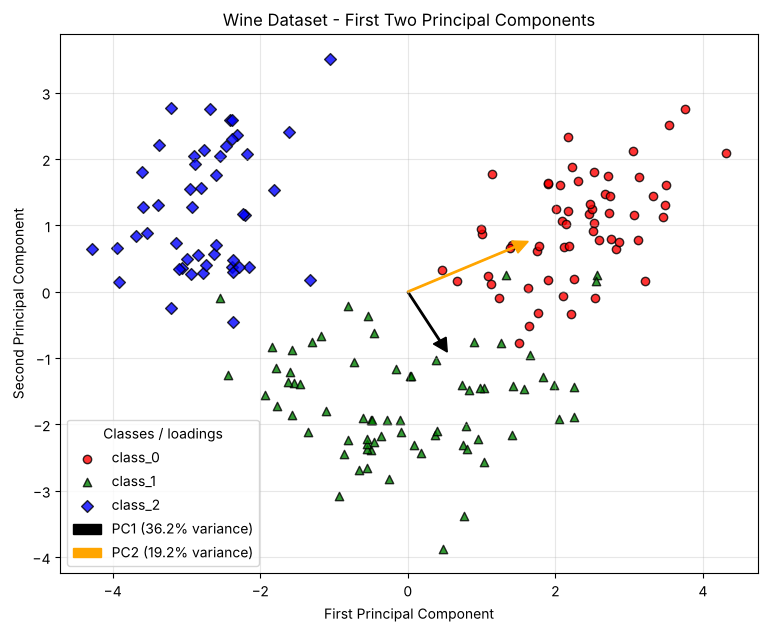

In [3]:
from sklearn.decomposition import PCA

pca_pipeline = Pipeline([
    ('scaler', StandardScaler()),     # always scale before PCA
    ('pca', PCA(n_components=2)),
])
X_pca = pca_pipeline.fit_transform(df_wine)

pca = pca_pipeline.named_steps['pca']
colors, shapes = ['r', 'g', 'b'], ['o', '^', 'D']

plt.figure(figsize=(9, 7))
for i, (shape, color) in enumerate(zip(shapes, colors)):
    plt.scatter(X_pca[target_wine == i, 0], X_pca[target_wine == i, 1],
                c=color, marker=shape, label=wine.target_names[i], edgecolor='k', alpha=.8)
for i, (comp, ratio) in enumerate(zip(pca.components_, pca.explained_variance_ratio_)):
    plt.arrow(0, 0, comp[0]*3, comp[1]*3, color=['black', 'orange'][i], width=0.02,
              head_width=0.2, head_length=0.2, label=f'PC{i+1} ({ratio:.1%} variance)')
plt.xlabel('First Principal Component'); plt.ylabel('Second Principal Component')
plt.title('Wine Dataset - First Two Principal Components')
plt.legend(title='Classes / loadings'); plt.grid(alpha=.3); plt.show()

Even though PCA never saw the labels, the three wine classes are already largely separated. The arrows show the direction of the loading vectors (scaled for visibility).

### How much variance is retained?

Explained variance ratio: [0.362  0.1921] | total: 55.41%


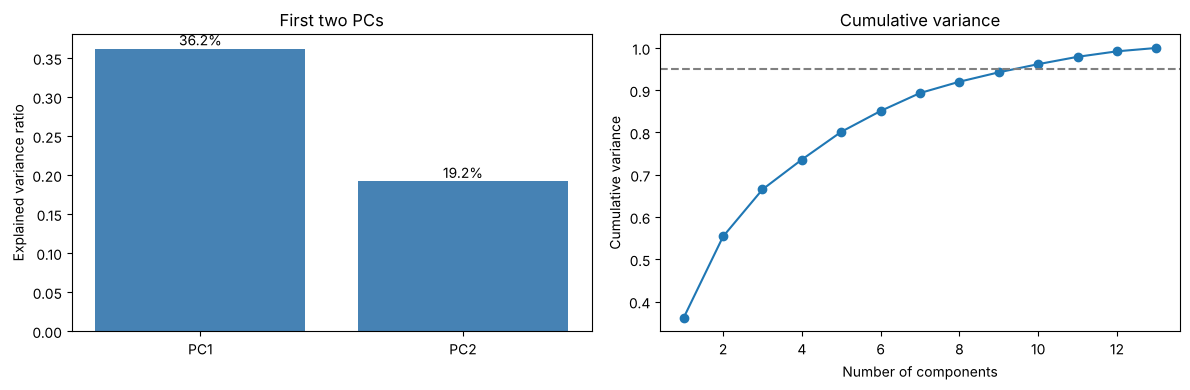

Components needed for 95% variance: 10


In [4]:
evr = pca.explained_variance_ratio_
print("Explained variance ratio:", evr.round(4), "| total:", f"{evr.sum():.2%}")

# Full PCA to see the whole spectrum (a "scree" view)
full = PCA().fit(StandardScaler().fit_transform(df_wine))
cum = np.cumsum(full.explained_variance_ratio_)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(['PC1', 'PC2'], evr, color='steelblue'); ax[0].set_title('First two PCs')
ax[0].set_ylabel('Explained variance ratio')
for k, v in enumerate(evr): ax[0].text(k, v, f'{v:.1%}', ha='center', va='bottom')
ax[1].plot(range(1, len(cum)+1), cum, 'o-'); ax[1].axhline(0.95, ls='--', c='gray')
ax[1].set_xlabel('Number of components'); ax[1].set_ylabel('Cumulative variance'); ax[1].set_title('Cumulative variance')
plt.tight_layout(); plt.show()
print("Components needed for 95% variance:", int(np.argmax(cum >= 0.95) + 1))

Two PCs already keep a bit over half of the total variance (the book reports ≈55.4%). The cumulative curve is the practical tool for choosing $m$: pick the smallest number reaching a target (commonly 90–95%). You can even pass `PCA(n_components=0.95)` to do this automatically.

## 3. LDA — Linear Discriminant Analysis

### Summary
A **supervised** technique: it finds axes that **maximise separation between classes** while keeping each class compact. Number of components $\le\min(p,\;\text{n\_classes}-1)$ — here $\min(13,2)=2$.

### Theory explained
Define

- **Within-class scatter** $S_W=\sum_{c}\sum_{\mathbf x\in c}(\mathbf x-\boldsymbol\mu_c)(\mathbf x-\boldsymbol\mu_c)^T$,
- **Between-class scatter** $S_B=\sum_c n_c(\boldsymbol\mu_c-\boldsymbol\mu)(\boldsymbol\mu_c-\boldsymbol\mu)^T$.

LDA chooses directions $\mathbf w$ maximising the **Fisher criterion**

$$J(\mathbf w)=\frac{\mathbf w^T S_B\mathbf w}{\mathbf w^T S_W\mathbf w}$$

i.e. *far-apart class means, tight classes*. Assumptions: each class is Gaussian with a **shared covariance matrix**.

### PCA vs LDA
| | PCA | LDA |
|:--|:--|:--|
| Labels | not used (unsupervised) | required (supervised) |
| Objective | maximise total variance | maximise class separability |
| Components | up to $p$ | up to $C-1$ |
| Typical use | exploration, noise reduction | preprocessing for classification |

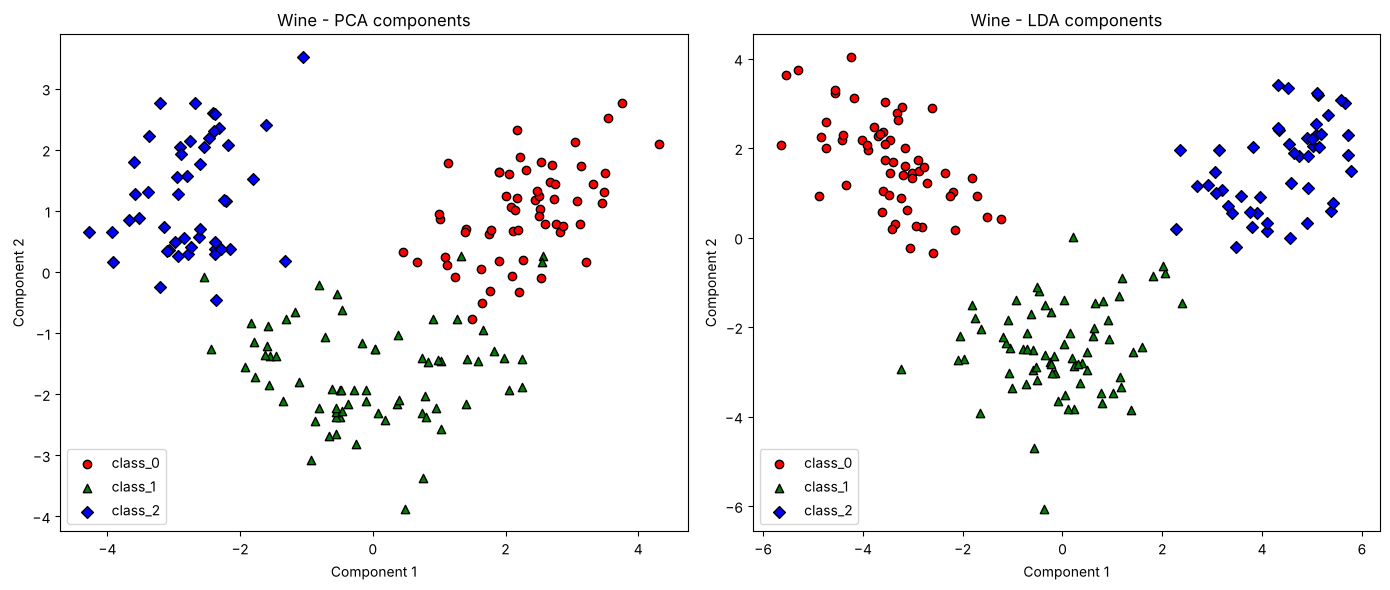

In [5]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

X_wine, y_wine = wine.data, wine.target
lda_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lda', LinearDiscriminantAnalysis(n_components=2)),
])
X_lda = lda_pipeline.fit_transform(X_wine, y_wine)      # NOTE: y is required

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, Z, name in [(axes[0], X_pca, 'PCA'), (axes[1], X_lda, 'LDA')]:
    for i, (shape, color) in enumerate(zip(shapes, colors)):
        ax.scatter(Z[y_wine == i, 0], Z[y_wine == i, 1], c=color, marker=shape,
                   edgecolor='k', label=wine.target_names[i])
    ax.set_title(f'Wine - {name} components'); ax.set_xlabel('Component 1'); ax.set_ylabel('Component 2'); ax.legend()
plt.tight_layout(); plt.show()

LDA separates the classes more sharply than PCA — partly *because* it uses the labels. Caveat: if you evaluate a classifier on LDA output, you must fit LDA **inside** cross-validation (e.g. in a `Pipeline`), otherwise label information leaks.

## 4. t-SNE and Data Visualisation

### Summary
t-SNE (t-distributed Stochastic Neighbour Embedding) is a **non-linear** method for **visualising** high-dimensional data in 2-D/3-D by preserving **local neighbourhoods**. Dataset used: `load_digits` — 1,797 handwritten digits, 8×8 pixels = 64 features, 10 classes.

### Theory explained
1. **High-dimensional similarities:** for points $i,j$ define a Gaussian conditional probability
$$p_{j|i}=\frac{\exp(-\lVert\mathbf x_i-\mathbf x_j\rVert^2/2\sigma_i^2)}{\sum_{k\ne i}\exp(-\lVert\mathbf x_i-\mathbf x_k\rVert^2/2\sigma_i^2)}$$
where $\sigma_i$ is set by the **perplexity** hyper-parameter (≈ effective number of neighbours).
2. **Low-dimensional similarities:** $q_{ij}\propto(1+\lVert\mathbf y_i-\mathbf y_j\rVert^2)^{-1}$ — a heavy-tailed **Student-t** (1 d.o.f.) distribution, which lets moderately distant points sit far apart and relieves the "crowding problem".
3. **Optimise** the positions $\mathbf y_i$ by gradient descent to minimise the **KL divergence** $\mathrm{KL}(P\Vert Q)=\sum_{i\ne j}p_{ij}\log\frac{p_{ij}}{q_{ij}}$.

**Cautions:** cluster sizes and between-cluster distances in a t-SNE plot are **not** reliably meaningful; results vary with `perplexity` and seed; it has no `transform()` for new data (so it is for visualisation, not preprocessing); it is slow for large $n$.

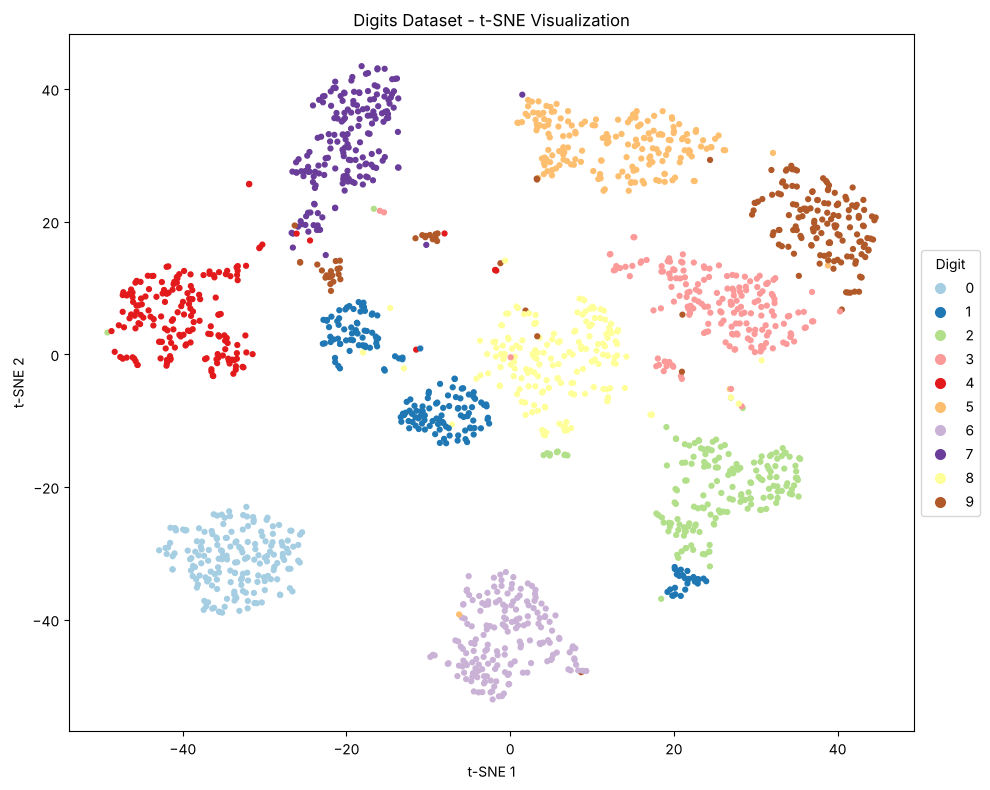

In [6]:
from sklearn.datasets import load_digits
from sklearn.manifold import TSNE

digits = load_digits()
tsne_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('tsne', TSNE(n_components=2, random_state=2024)),
])
X_tsne = tsne_pipeline.fit_transform(digits.data)

plt.figure(figsize=(10, 8))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=digits.target, cmap='Paired', s=12)
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=plt.cm.Paired(i/9), label=str(i), markersize=9) for i in range(10)]
plt.legend(handles=handles, title='Digit', loc='center left', bbox_to_anchor=(1, .5))
plt.title('Digits Dataset - t-SNE Visualization'); plt.xlabel('t-SNE 1'); plt.ylabel('t-SNE 2')
plt.tight_layout(); plt.show()

The ten digits form distinct islands. Visually similar digits (e.g. 4/7/9) sit near each other, while "0" is largely isolated — the plot reflects real similarity structure in pixel space.

## 5. Choosing a Technique and the Trade-offs

| Technique | Type | Purpose | Key feature | Best for |
|:--|:--|:--|:--|:--|
| **PCA** | Unsupervised, linear | Reduction / extraction | Maximises variance | Exploration, denoising, speed-ups |
| **LDA** | Supervised, linear | Reduction for classification | Maximises class separation | Classification pre-processing |
| **t-SNE** | Unsupervised, non-linear | Visualisation | Preserves local structure | Exploring clusters in 2-D/3-D |

**Decision factors:** labels available? · variance vs separability goal? · extraction vs visualisation? · efficiency (PCA fastest, t-SNE slowest) · interpretability (PCs are linear mixes; t-SNE axes have no meaning).

**Trade-offs**
- Complexity vs interpretability — fewer features are simpler, but information may be lost.
- Training time vs accuracy — faster, but discarding too much hurts accuracy.
- Overfitting vs underfitting — removing noise helps; removing too much underfits.

A common combo: **PCA first** (e.g. to 30–50 dims), **then t-SNE** — faster and denoised.

## 6. Practical Exercises

### Exercise 1 — PCA before logistic regression (Iris)
Compare a classifier with and without PCA.

In [7]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score

iris = load_iris()
Xtr, Xte, ytr, yte = train_test_split(iris.data, iris.target, test_size=0.3, random_state=2024, stratify=iris.target)

no_pca = Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000))])
with_pca = Pipeline([('scaler', StandardScaler()), ('pca', PCA(n_components=2)), ('clf', LogisticRegression(max_iter=1000))])

for name, p in [("Without PCA (4 features)", no_pca), ("With PCA (2 components)", with_pca)]:
    p.fit(Xtr, ytr)
    cv = cross_val_score(p, Xtr, ytr, cv=5).mean()
    print(f"{name:26s} test acc = {p.score(Xte, yte):.3f} | 5-fold CV acc = {cv:.3f}")

Without PCA (4 features)   test acc = 0.956 | 5-fold CV acc = 0.971
With PCA (2 components)    test acc = 0.911 | 5-fold CV acc = 0.905


Going from 4 features to 2 components lowers accuracy modestly here (roughly 0.96 → 0.91 on the test set, 0.97 → 0.91 in CV): most, but not all, of the useful information lives in the first two directions. That is the trade-off in action — a simpler model for a small accuracy cost. Note that the PCA step sits inside the pipeline so it is re-fit within each CV fold.

### Exercise 2 — t-SNE + K-Means on Digits
Cluster the 2-D embedding and compare cluster labels with the true labels.

Adjusted Rand Index (clusters vs true digits): 0.77


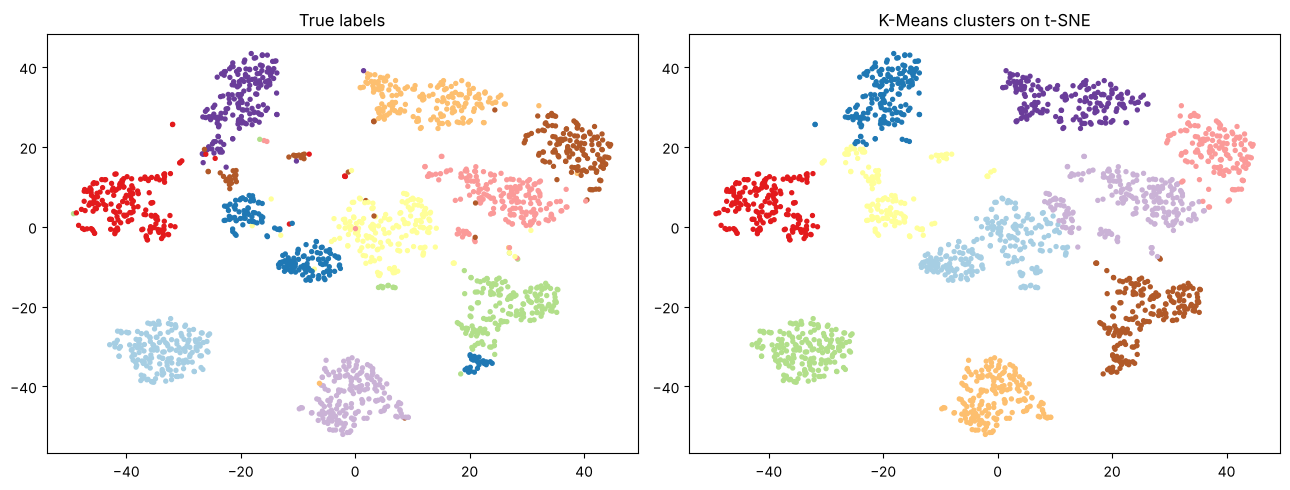

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

km = KMeans(n_clusters=10, random_state=2024, n_init=10).fit(X_tsne)
print("Adjusted Rand Index (clusters vs true digits):", round(adjusted_rand_score(digits.target, km.labels_), 3))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=digits.target, cmap='Paired', s=8); ax[0].set_title('True labels')
ax[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=km.labels_, cmap='Paired', s=8); ax[1].set_title('K-Means clusters on t-SNE')
plt.tight_layout(); plt.show()

An ARI of 1 would mean the clusters match the true digits perfectly and 0 means chance level; a value around 0.77 means K-Means recovers most, but not all, of the digit structure (a few touching islands get merged or split). K-Means works reasonably *on the embedding* because t-SNE already made the clusters compact — but t-SNE distances are not globally meaningful, so treat this as exploratory.

---
## Chapter 3 Summary
- Reduce dimensions to simplify, speed up, regularise and visualise.
- **PCA** = unsupervised, maximises variance, *standardize first*, choose components via cumulative explained variance.
- **LDA** = supervised, maximises class separation, at most $C-1$ components.
- **t-SNE** = non-linear, visualisation only, sensitive to perplexity, no `transform` for new data.
- Always evaluate the effect on downstream model performance, inside a `Pipeline`.